# Computational Comparison of Vitamin C Content in Citrus Fruits Using DCPIP

## Project Overview

This project develops a computational model inspired by a vitamin C
analysis experiment I performed during high school.

The original experiment used DCPIP to investigate the presence of
ascorbic acid (vitamin C) in citrus fruit juices and vitamin C reference
samples.

Because laboratory equipment is not currently available to me, this
project recreates the quantitative data-analysis component using Python.

## Objectives

- Model vitamin C analysis using DCPIP titration data
- Develop a calibration relationship between vitamin C concentration
  and DCPIP volume
- Estimate vitamin C concentration in simulated citrus samples
- Compare simulated vitamin C concentrations between different fruits
- Analyze measurement uncertainty
- Visualize the results using scientific graphs

## Important Note

The numerical data used in the computational analysis are simulated
examples based on the experimental procedure. They are not presented
as measurements obtained from my original high-school experiment.

## Chemical Principle

DCPIP is a redox indicator commonly used in vitamin C analysis.

Vitamin C (ascorbic acid) acts as a reducing agent and reduces the
colored DCPIP reagent, resulting in a loss of color.

The amount of DCPIP required to reach the endpoint can therefore be
related to the amount of vitamin C present.

The computational model assumes a simplified proportional relationship
between the amount of vitamin C and the DCPIP volume required.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
standards = {
    "Vitamin_C_mg_L": [20, 40, 60, 80, 100],
    "DCPIP_volume_mL": [2.0, 4.0, 6.1, 7.9, 10.1]
}

calibration_df = pd.DataFrame(standards)

calibration_df

,Vitamin_C_mg_L,DCPIP_volume_mL
0,20,2.0
1,40,4.0
2,60,6.1
3,80,7.9
4,100,10.1


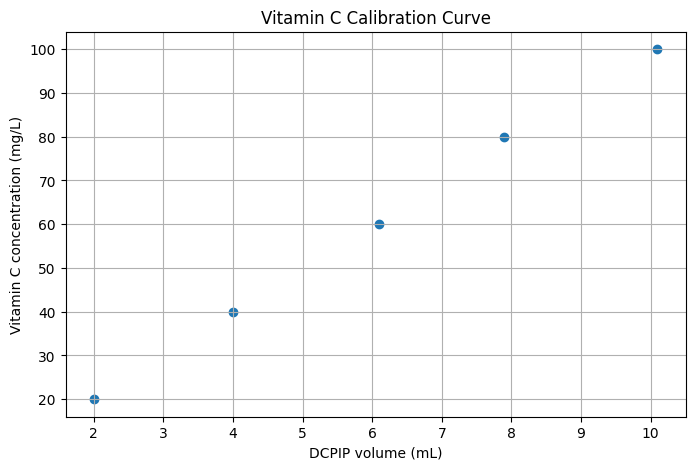

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    calibration_df["DCPIP_volume_mL"],
    calibration_df["Vitamin_C_mg_L"]
)

plt.xlabel("DCPIP volume (mL)")
plt.ylabel("Vitamin C concentration (mg/L)")
plt.title("Vitamin C Calibration Curve")

plt.grid(True)
plt.show()

In [ ]:
slope, intercept = np.polyfit(
    calibration_df["DCPIP_volume_mL"],
    calibration_df["Vitamin_C_mg_L"],
    1
)

print("Slope:", round(slope, 3))
print("Intercept:", round(intercept, 3))

Slope: 9.944
Intercept: 0.14


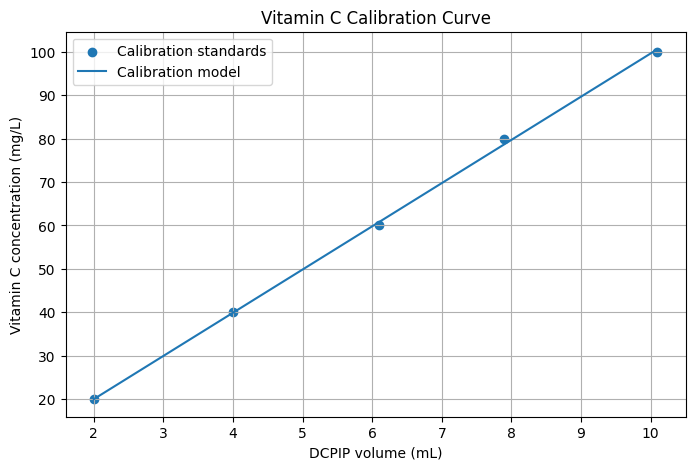

In [ ]:
predicted_vitamin_c = (
    slope * calibration_df["DCPIP_volume_mL"]
    + intercept
)

plt.figure(figsize=(8, 5))

plt.scatter(
    calibration_df["DCPIP_volume_mL"],
    calibration_df["Vitamin_C_mg_L"],
    label="Calibration standards"
)

plt.plot(
    calibration_df["DCPIP_volume_mL"],
    predicted_vitamin_c,
    label="Calibration model"
)

plt.xlabel("DCPIP volume (mL)")
plt.ylabel("Vitamin C concentration (mg/L)")
plt.title("Vitamin C Calibration Curve")

plt.legend()
plt.grid(True)

plt.savefig(
    "vitamin_c_calibration_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
r_squared = np.corrcoef(
    calibration_df["DCPIP_volume_mL"],
    calibration_df["Vitamin_C_mg_L"]
)[0, 1] ** 2

print("R² =", round(r_squared, 4))

R² = 0.9993


In [ ]:
unknown_samples = {
    "Fruit": ["Lemon", "Orange", "Mandarin"],
    "DCPIP_volume_mL": [4.2, 5.8, 3.6]
}

unknown_df = pd.DataFrame(unknown_samples)

unknown_df

,Fruit,DCPIP_volume_mL
0,Lemon,4.2
1,Orange,5.8
2,Mandarin,3.6


In [ ]:
unknown_df["Estimated_Vitamin_C_mg_L"] = (
    slope * unknown_df["DCPIP_volume_mL"]
    + intercept
)

unknown_df["Estimated_Vitamin_C_mg_L"] = (
    unknown_df["Estimated_Vitamin_C_mg_L"].round(2)
)

unknown_df

,Fruit,DCPIP_volume_mL,Estimated_Vitamin_C_mg_L
0,Lemon,4.2,41.90
1,Orange,5.8,57.81
2,Mandarin,3.6,35.94


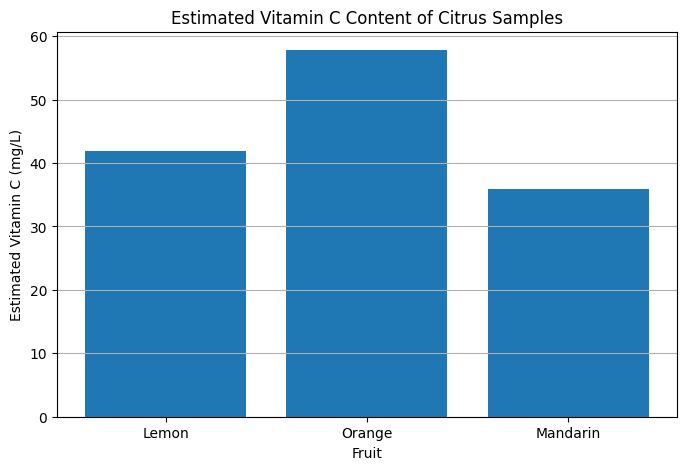

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    unknown_df["Fruit"],
    unknown_df["Estimated_Vitamin_C_mg_L"]
)

plt.xlabel("Fruit")
plt.ylabel("Estimated Vitamin C (mg/L)")
plt.title("Estimated Vitamin C Content of Citrus Samples")

plt.grid(axis="y")
plt.show()

In [ ]:
highest_vitamin_c = unknown_df.loc[
    unknown_df["Estimated_Vitamin_C_mg_L"].idxmax()
]

print(
    "Sample with the highest estimated vitamin C:",
    highest_vitamin_c["Fruit"]
)

print(
    "Estimated concentration:",
    highest_vitamin_c["Estimated_Vitamin_C_mg_L"],
    "mg/L"
)

Sample with the highest estimated vitamin C: Orange
Estimated concentration: 57.81 mg/L


In [ ]:
dcpip_uncertainty = 0.1

print("Assumed DCPIP volume uncertainty: ±",
      dcpip_uncertainty, "mL")

Assumed DCPIP volume uncertainty: ± 0.1 mL


In [ ]:
vitamin_c_uncertainty = slope * dcpip_uncertainty

print(
    "Estimated vitamin C uncertainty: ±",
    round(vitamin_c_uncertainty, 2),
    "mg/L"
)

Estimated vitamin C uncertainty: ± 0.99 mg/L


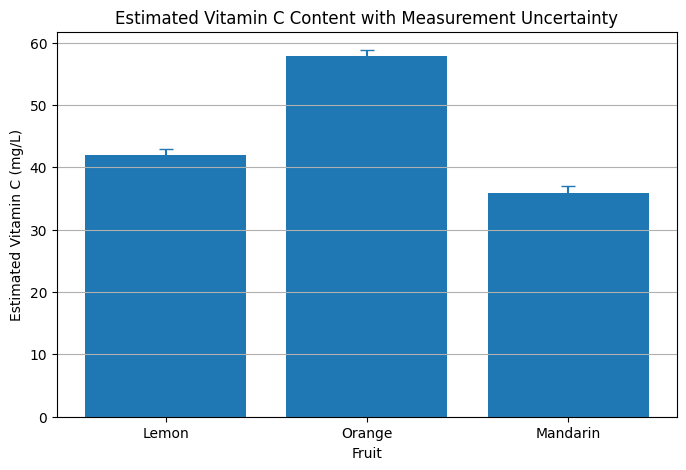

In [ ]:
plt.figure(figsize=(8, 5))

plt.bar(
    unknown_df["Fruit"],
    unknown_df["Estimated_Vitamin_C_mg_L"]
)

plt.errorbar(
    unknown_df["Fruit"],
    unknown_df["Estimated_Vitamin_C_mg_L"],
    yerr=vitamin_c_uncertainty,
    fmt="none",
    capsize=5
)

plt.xlabel("Fruit")
plt.ylabel("Estimated Vitamin C (mg/L)")
plt.title("Estimated Vitamin C Content with Measurement Uncertainty")

plt.grid(axis="y")

plt.savefig(
    "vitamin_c_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
final_results = unknown_df.copy()

final_results["Uncertainty_mg_L"] = round(
    vitamin_c_uncertainty,
    2
)

final_results

,Fruit,DCPIP_volume_mL,Estimated_Vitamin_C_mg_L,Uncertainty_mg_L
0,Lemon,4.2,41.90,0.99
1,Orange,5.8,57.81,0.99
2,Mandarin,3.6,35.94,0.99


In [ ]:
final_results.to_excel(
    "vitamin_c_analysis_results.xlsx",
    index=False
)

print("Excel file created successfully!")

Excel file created successfully!


In [ ]:
final_results.to_csv(
    "vitamin_c_analysis_results.csv",
    index=False
)

print("CSV file created successfully!")

CSV file created successfully!


# Results and Discussion

A computational calibration model was developed to relate DCPIP volume
to vitamin C concentration.

The simulated calibration standards showed an approximately linear
relationship between DCPIP volume and vitamin C concentration.

The calibration model was subsequently used to estimate the vitamin C
concentration of simulated lemon, orange and mandarin juice samples.

The analysis demonstrates how a calibration curve can transform an
experimental measurement into a quantitative estimate of an unknown
concentration.

Measurement uncertainty was also incorporated into the model to
investigate how uncertainty in DCPIP volume affects the estimated
vitamin C concentration.

## Limitations

The numerical values used in this computational project are simulated
and are not measurements from the original high-school experiment.

The model assumes a simplified linear relationship between DCPIP volume
and vitamin C concentration. Real analytical measurements may be
affected by reagent concentration, endpoint detection, sample
preparation, matrix effects and other experimental factors.

## Future Work

A future laboratory investigation could generate experimental calibration
data and compare the resulting calibration model with the computational
model developed here.

# Skills Demonstrated

### Chemistry
- Redox chemistry
- Vitamin C analysis
- DCPIP indicator method
- Quantitative analytical chemistry

### Programming
- Python
- Pandas
- NumPy
- Matplotlib
- DataFrames

### Data Analysis
- Calibration curves
- Linear regression
- Correlation
- R² analysis
- Uncertainty analysis
- Comparative analysis

### Scientific Communication
- Data visualization
- Results interpretation
- Identification of assumptions
- Discussion of limitations

# Portfolio Summary

## Computational Vitamin C Analysis Using DCPIP

**Type:** Independent computational analytical chemistry project

**Tools:** Python, Google Colab, Pandas, NumPy, Matplotlib

### What I did

I transformed a vitamin C analysis experiment that I had previously
performed in high school into a computational analytical chemistry
project.

I developed a simulated calibration model relating DCPIP volume to
vitamin C concentration and used this model to estimate vitamin C
concentrations in simulated citrus juice samples.

I then analyzed the results statistically, visualized the comparison
between samples and investigated the effect of measurement uncertainty
on the calculated concentrations.

### Why I built it

I wanted to explore how computational tools can complement experimental
chemistry and how calibration models can be used to transform
experimental measurements into quantitative information.

### Key learning

This project strengthened my understanding of redox chemistry,
calibration methods, quantitative analysis, Python programming,
scientific visualization and measurement uncertainty.

### Important distinction

The experimental procedure was based on my previous high-school
experience. The numerical data used in this computational project were
simulated and are not presented as original laboratory measurements.